# Módulo 5 — Métricas complementarias para validar con datos reales

Complemento del **Día 9** (ver [`README.md`](../README.md#métricas-complementarias)).
Las funciones del Día 8 (`metricas.py`) suponen series completas y
variables lineales. Con datos reales eso casi nunca pasa: faltan horas, hay
datos malos, la dirección del viento es circular y la humedad del `wrfout`
no viene como la mide la estación.

Este notebook usa el módulo [`evaluacion.py`](evaluacion.py), que agrega:

| Problema | Función |
|---|---|
| Horas sin dato (NaN) | `pares_validos`, `resumen_metricas` (con IOA) |
| Datos malos en la estación | `control_calidad`, `completitud` |
| Humedad | `humedad_relativa_wrf`, `razon_mezcla`, `presion_por_altura` |
| Dirección del viento | `velocidad_direccion`, `metricas_direccion` |
| ¿El punto de grilla representa a la estación? | `revisar_emparejamiento`, `corregir_t2_altura` |
| ¿Es bueno o malo el resultado? | `BENCHMARKS`, `evaluar_benchmarks` |

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import evaluacion as ev
from metricas import calcular_rmse

DATOS = "../../../data"

## 1. Horas sin dato: comparar solo pares válidos

Abrimos el `wrfout` de muestra con `abrir_wrfout`, que deja solo las
variables que vamos a usar. Los `wrfout` de un proyecto real suelen traer
cientos de variables y pesar varios GB; así no se carga nada que no haga
falta.

In [2]:
ds_wrf = ev.abrir_wrfout(f"{DATOS}/grid_muestra/wrfout_muestra.nc", ["T2", "U10", "V10"])
tiempos = pd.to_datetime(ds_wrf["XTIME"].values)
dx_km = 3.0   # DX del wrfout de muestra (atributo DX = 3000 m)

coords = json.load(open(f"{DATOS}/ogimet/coords_area_wrf.json"))

def punto_mas_cercano(ds, lat, lon):
    dist2 = (ds["XLAT"] - lat) ** 2 + (ds["XLONG"] - lon) ** 2
    return np.unravel_index(np.argmin(dist2.values), dist2.shape)

c = coords["Carrasco"]
iy, ix = punto_mas_cercano(ds_wrf, c["lat"], c["lon"])
obs_carrasco = (pd.read_csv(f"{DATOS}/obs/Carrasco_2024_12_13_horario.csv", parse_dates=["tiempo"])
                .set_index("tiempo").reindex(tiempos))
sim_t2 = ds_wrf["T2"].isel(south_north=iy, west_east=ix).values - 273.15

print("Horas sin temperatura observada en Carrasco:", int(obs_carrasco["temp_C"].isna().sum()), "de", len(tiempos))
print("RMSE con la función del Día 8:", calcular_rmse(sim_t2, obs_carrasco["temp_C"].values))

Horas sin temperatura observada en Carrasco: 1 de 24
RMSE con la función del Día 8: nan


Basta **un** NaN para que `np.mean` devuelva NaN y la métrica se pierda.
`resumen_metricas` primero se queda con los pares donde hay dato en los dos
lados, informa cuántos quedaron (`n`) y agrega el **IOA** (índice de
concordancia de Willmott): va de 0 a 1, y a diferencia de `r` castiga
también el sesgo. Si quedan menos de `n_min` pares (10 por defecto),
devuelve NaN en vez de un número poco confiable.

In [3]:
pd.Series(ev.resumen_metricas(sim_t2, obs_carrasco["temp_C"].values)).round(3)

n       23.000
bias     1.555
MAE      1.555
RMSE     1.735
r        0.976
IOA      0.876
KGE      0.704
dtype: float64

## 2. Control de calidad de la estación

En el Módulo 6, un solo dato de Lima-Callao baja la correlación de 0,84 a
0,57. Ese dato se encontró mirando el gráfico. `control_calidad` lo busca
solo, con tres reglas simples:

- **fuera_rango:** valores imposibles (`ev.LIMITES`).
- **pico:** un dato que se aleja de golpe del anterior **y** del siguiente,
  en la misma dirección (`ev.SALTO_MAX`: 6 °C para la temperatura).
- **repetido:** el mismo valor muchas horas seguidas, como un sensor
  trabado (`ev.REPETIDOS`). No cuenta los valores que sí pueden repetirse:
  0 mm de lluvia, viento en calma y humedad de 100 % (neblina o garúa).

                     fuera_rango  pico  repetido
tiempo                                          
2025-03-16 18:00:00        False  True     False
Completitud (cada 3 h): 99.2%


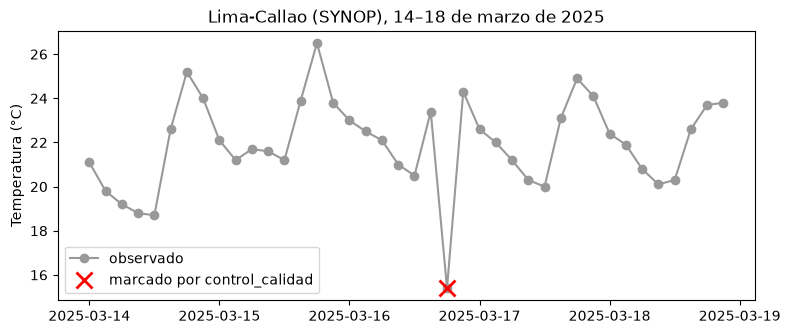

In [4]:
lima = pd.read_csv(f"{DATOS}/obs/Lima_2025_03_horario.csv", parse_dates=["tiempo"]).set_index("tiempo")
t_limpia, marcas = ev.control_calidad(lima["temp_C"], "temp_C")
print(marcas)
print(f"Completitud (cada 3 h): {ev.completitud(lima['temp_C'], '2025-03-01', '2025-03-31 21:00', freq='3h'):.1%}")

tramo = slice("2025-03-14", "2025-03-18")
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(lima.loc[tramo, "temp_C"], "o-", color="0.6", label="observado")
ax.plot(lima.loc[marcas.index, "temp_C"], "rx", ms=12, mew=2, label="marcado por control_calidad")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Lima-Callao (SYNOP), 14–18 de marzo de 2025")
ax.legend()
plt.show()

**Qué marcó:** un solo dato, el del 16 de marzo a las 18:00 UTC: 15,4 °C entre 23,4 °C (15:00) y 24,3 °C (21:00). Es el mismo dato dudoso del Módulo 6. Bajar 8 °C en 3 horas y volver a subir 9 °C, en una tarde de verano en Lima, no es físico.

Marcar no es borrar a ciegas: la serie limpia lo cambia por NaN, pero conviene mirar el gráfico, decidir y anotar en el informe qué datos se descartaron y por qué.

Ahora las 5 estaciones automáticas de SENAMHI en Lima (marzo de 2025,
cada hora). Se leen como en el Módulo 6: separador `;`, `S/D` como faltante
y hora local (UTC−5) pasada a UTC.

In [5]:
estaciones = json.load(open(f"{DATOS}/senamhi/estaciones_lima.json"))

def leer_senamhi(archivo):
    df = pd.read_csv(f"{DATOS}/senamhi/{archivo}", sep=";", na_values="S/D", dtype={"Hora": str})
    fecha = pd.to_datetime(df["Año"].astype(str) + "-" + df["Mes"].astype(str) + "-"
                           + df["Día"].astype(str) + " " + df["Hora"])
    df.index = fecha + pd.Timedelta(hours=5)   # hora local -> UTC
    return df.rename(columns={"Temperatura (°C)": "temp_C", "Humedad (%)": "hr",
                              "Vel. Viento (m/s)": "vel_viento_ms", "Dir. Viento (°)": "dir_viento_deg"})

senamhi = {e["nombre"]: leer_senamhi(e["archivo"]) for e in estaciones}

filas = []
for e in estaciones:
    df = senamhi[e["nombre"]]
    for variable in ["temp_C", "hr", "vel_viento_ms"]:
        if variable not in df:
            continue   # Ceres no mide humedad
        _, m = ev.control_calidad(df[variable], variable)
        filas.append({"estacion": e["nombre"], "variable": variable,
                      "completitud": ev.completitud(df[variable], "2025-03-01 05:00", "2025-04-01 04:00"),
                      "marcados": len(m)})
pd.DataFrame(filas).set_index(["estacion", "variable"]).round(3)

completitud  marcados
estacion             variable                            
San Martín de Porres temp_C               0.991         0
                     hr                   0.988         0
                     vel_viento_ms        0.991         0
Campo de Marte       temp_C               0.997         0
                     hr                   0.997         0
                     vel_viento_ms        0.996         0
Von Humboldt         temp_C               0.999         0
                     hr                   0.999         0
                     vel_viento_ms        0.999         0
Ceres                temp_C               0.991         0
                     vel_viento_ms        0.991         0
Ñaña                 temp_C               0.997         0
                     hr                   0.996         0
                     vel_viento_ms        0.995         0

**Qué muestra la tabla:** las 5 estaciones están casi completas (98,8 % o más) y ninguna regla marca datos. Eso no prueba que los datos sean perfectos: estas reglas solo atrapan errores groseros.

Un caso para mirar: San Martín de Porres tiene 31 horas, en tramos de 6 horas o más, con humedad de **100 %**. Con la regla del valor repetido sin excepciones, se habrían marcado como sensor trabado. No se marcan porque el aire saturado es normal de noche en la costa de Lima (neblina, garúa). Por eso existe `ev.VALOR_NORMAL_REPETIDO`: una regla de control de calidad tiene que conocer el clima del lugar.

## 3. Humedad: del `wrfout` a lo que mide la estación

El `wrfout` no trae humedad relativa: trae `Q2`, la **razón de mezcla** a
2 m (kg de vapor por kg de aire seco). Para compararla con una estación hay
dos caminos:

- Pasar el modelo a **humedad relativa** con `T2`, `Q2` y `PSFC`
  (`humedad_relativa_wrf`).
- Pasar la estación a **razón de mezcla** con su temperatura, su HR y la
  presión (`razon_mezcla`). Es la que usan los criterios de Emery et al.
  (2001), porque no depende de la temperatura como la HR. Las estaciones de
  SENAMHI no miden presión: se estima con la altura (`presion_por_altura`).

HR a 2 m del wrfout: mínimo 47 %, máximo 100 %


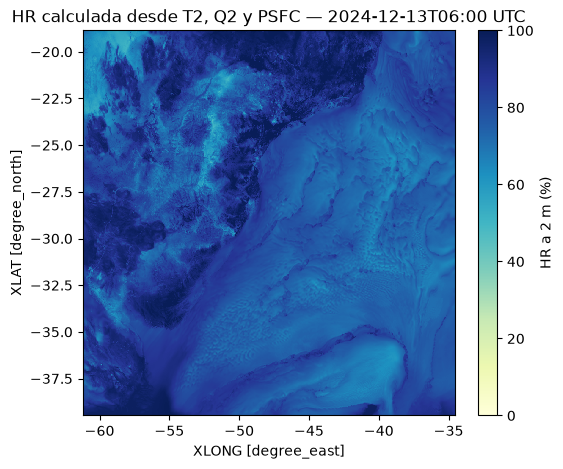

In [6]:
ds_3d = ev.abrir_wrfout(f"{DATOS}/grid_muestra/wrfout_real_muestra.nc", ["T2", "Q2", "PSFC"])
hr_wrf = ev.humedad_relativa_wrf(ds_3d["T2"], ds_3d["Q2"], ds_3d["PSFC"])
print(f"HR a 2 m del wrfout: mínimo {float(hr_wrf.min()):.0f} %, máximo {float(hr_wrf.max()):.0f} %")

fig, ax = plt.subplots(figsize=(6, 5))
hr_wrf.isel(Time=0).plot(ax=ax, x="XLONG", y="XLAT", cmap="YlGnBu", vmin=0, vmax=100,
                         cbar_kwargs={"label": "HR a 2 m (%)"})
ax.set_title(f"HR calculada desde T2, Q2 y PSFC — {str(ds_3d['XTIME'].values[0])[:16]} UTC")
plt.show()

In [7]:
e = next(e for e in estaciones if e["nombre"].startswith("Ñaña"))
df = senamhi[e["nombre"]]
p_est = ev.presion_por_altura(e["alt_m"])
q_obs = ev.razon_mezcla(df["temp_C"], df["hr"], p_est)

print(f"{e['nombre']} ({e['alt_m']} m): presión estándar estimada {p_est:.0f} hPa")
print(f"Razón de mezcla en marzo: media {q_obs.mean():.1f} g/kg, rango {q_obs.min():.1f}–{q_obs.max():.1f} g/kg")

Ñaña (553 m): presión estándar estimada 949 hPa
Razón de mezcla en marzo: media 13.2 g/kg, rango 10.6–16.5 g/kg


**Cómo leerlo:** la HR del `wrfout` va de 47 % a 100 %, valores posibles. Es una primera comprobación de que `T2`, `Q2` y `PSFC` se combinaron bien: si saliera mayor que 100 % en muchos puntos, o negativa, habría un error de unidades (por ejemplo, `PSFC` en hPa en vez de Pa).

En Ñaña la razón de mezcla media de marzo es 13,2 g/kg. El criterio de Emery et al. (2001) pide un error de humedad de 2 g/kg o menos, alrededor del 15 % de ese valor.

## 4. Dirección del viento: una variable circular

El notebook `04_entregable_automatizacion` validó solo la velocidad,
porque la dirección es circular: 350° y 10° están a 20° de distancia, no a
340°. `diferencia_angular` lleva cada diferencia al rango −180° a 180°, y
con eso ya se pueden calcular el sesgo y el error medio (`metricas_direccion`).
Con viento muy flojo la dirección no está bien definida, así que se
descartan las horas con menos de 1 m/s observado.

`velocidad_direccion` convierte `U10`/`V10` en velocidad y dirección. En
este dominio (Mercator) `U10`/`V10` ya apuntan al este y al norte; en un
dominio Lambert hay que pasarle `SINALPHA` y `COSALPHA` para girarlos
(Módulo 4).

In [8]:
import xarray as xr
era5 = xr.open_dataset(f"{DATOS}/era_muestra/era5_land_20241213.nc")

filas = []
for nombre, c in coords.items():
    obs = (pd.read_csv(f"{DATOS}/obs/{nombre}_2024_12_13_horario.csv", parse_dates=["tiempo"])
           .set_index("tiempo").reindex(tiempos))
    iy, ix = punto_mas_cercano(ds_wrf, c["lat"], c["lon"])
    vel_w, dir_w = ev.velocidad_direccion(ds_wrf["U10"].isel(south_north=iy, west_east=ix),
                                          ds_wrf["V10"].isel(south_north=iy, west_east=ix))
    punto_era5 = dict(latitude=c["lat"], longitude=c["lon"], method="nearest")
    vel_e, dir_e = ev.velocidad_direccion(era5["u10"].sel(**punto_era5), era5["v10"].sel(**punto_era5))
    filas.append(pd.DataFrame({
        "estacion": nombre, "temp_obs": obs["temp_C"].values,
        "temp_wrf": ds_wrf["T2"].isel(south_north=iy, west_east=ix).values - 273.15,
        "temp_era5": era5["t2m"].sel(**punto_era5).values - 273.15,
        "vel_obs": obs["vel_viento_ms"].values, "vel_wrf": vel_w, "vel_era5": vel_e,
        "dir_obs": obs["dir_viento_deg"].values, "dir_wrf": dir_w, "dir_era5": dir_e,
    }, index=tiempos))
tabla = pd.concat(filas)

con_viento = tabla[tabla["vel_obs"] >= 1.0]   # las mismas horas que usa metricas_direccion
for fuente in ["wrf", "era5"]:
    lineal = np.nanmean(np.abs(con_viento[f"dir_{fuente}"] - con_viento["dir_obs"]))
    circ = ev.metricas_direccion(tabla[f"dir_{fuente}"], tabla["dir_obs"], vel_obs=tabla["vel_obs"])
    print(f"{fuente.upper():5s} error medio 'lineal': {lineal:5.1f}°   circular: {circ['MAE']:5.1f}°  "
          f"sesgo circular: {circ['bias']:+5.1f}°  (n={circ['n']})")

WRF   error medio 'lineal':  67.1°   circular:  49.2°  sesgo circular: -18.3°  (n=138)
ERA5  error medio 'lineal':  52.4°   circular:  44.5°  sesgo circular: -16.2°  (n=138)


**Qué cambia con la cuenta circular:** calculado como si fuera una variable lineal, el error medio sale 67° (WRF) y 52° (ERA5-Land). Con la diferencia circular baja a 49° y 44°. La diferencia viene de los pares que cruzan el norte (por ejemplo, 350° contra 10°), que la cuenta lineal toma como 340° de error.

Con el cálculo correcto, los dos modelos tienen un sesgo de −16° a −18°: su viento viene de una dirección girada en sentido antihorario respecto de la observada. Quedan n = 138 pares de 144: se descartaron las horas en calma (menos de 1 m/s) o sin dato.

## 5. ¿El punto de grilla representa a la estación?

`revisar_emparejamiento` hace dos preguntas antes de calcular métricas:

- **Distancia:** el punto más cercano nunca debería estar a más de ~0,7
  veces el tamaño de la celda (media diagonal). Si está más lejos, la
  estación cae fuera del dominio o latitud y longitud están al revés (el
  error que se provocó a propósito en el notebook `04`).
- **Altura:** si se le pasa la altura del modelo (variable `HGT` del
  `wrfout`) y la de la estación, avisa cuando difieren más de 100 m. La
  temperatura baja unos 6,5 °C por km: 300 m de diferencia son unos 2 °C de
  sesgo que no son culpa del modelo. `corregir_t2_altura` hace esa
  corrección.

In [9]:
filas = []
for nombre, c in coords.items():
    iy, ix = punto_mas_cercano(ds_wrf, c["lat"], c["lon"])
    r = ev.revisar_emparejamiento(c["lat"], c["lon"],
                                  float(ds_wrf["XLAT"][iy, ix]), float(ds_wrf["XLONG"][iy, ix]), dx_km)
    filas.append({"estacion": nombre, "dist_km": r["dist_km"], "avisos": "; ".join(r["avisos"]) or "ok"})

# El mismo error del notebook 04: lat y lon al reves
c = coords["Ezeiza"]
iy, ix = punto_mas_cercano(ds_wrf, c["lon"], c["lat"])
r = ev.revisar_emparejamiento(c["lat"], c["lon"],
                              float(ds_wrf["XLAT"][iy, ix]), float(ds_wrf["XLONG"][iy, ix]), dx_km)
filas.append({"estacion": "Ezeiza (lat/lon al revés)", "dist_km": r["dist_km"], "avisos": "; ".join(r["avisos"])})
pd.DataFrame(filas).set_index("estacion")

,dist_km,avisos
estacion,,
Carrasco,0.26,ok
Ezeiza,1.84,ok
Iguazu,1.44,ok
Resistencia,0.78,ok
Rosario,1.47,ok
Salto,0.97,ok
Ezeiza (lat/lon al revés),588.68,punto a 588.7 km (celda de 3.0 km): ¿fuera del...


El `wrfout` de muestra se recortó a 5 variables y no trae `HGT`, así que
aquí no se puede revisar la altura. Un `wrfout` completo sí la trae. Con
él, el uso es:

```python
hgt = ds["HGT"].isel(Time=0)
r = ev.revisar_emparejamiento(lat, lon, lat_mod, lon_mod, dx_km,
                              alt_est=e["alt_m"], alt_mod=float(hgt[iy, ix]))
t2_corregida = ev.corregir_t2_altura(t2_modelo_c, float(hgt[iy, ix]), e["alt_m"])
```

En Lima importa mucho: las 5 estaciones de SENAMHI van de 56 m (San
Martín de Porres) a 553 m (Ñaña), y con celdas de varios km la altura del
modelo puede ser muy distinta de la de la estación.

## 6. ¿Es bueno o malo? Criterios de desempeño

Un RMSE de 2 °C, ¿es bueno? Para no responder a ojo, se compara con
umbrales publicados para modelos meteorológicos (`ev.BENCHMARKS`):

- **Terreno simple:** Emery et al. (2001).
- **Terreno complejo** (montaña, costa con relieve, como Lima):
  Kemball-Cook et al. (2005), más tolerantes.

Revisa los valores contra los artículos antes de citarlos en un informe.
El dominio de muestra (llanura de Argentina y Uruguay) es terreno simple.

In [10]:
partes = []
for variable, columnas in [("temp", "temp"), ("vel", "vel")]:
    for fuente in ["wrf", "era5"]:
        resumen = ev.resumen_metricas(tabla[f"{columnas}_{fuente}"], tabla[f"{columnas}_obs"])
        partes.append(ev.evaluar_benchmarks(resumen, variable, terreno="simple")
                      .assign(variable=variable, fuente=fuente.upper(), n=resumen["n"]))
for fuente in ["wrf", "era5"]:
    resumen = ev.metricas_direccion(tabla[f"dir_{fuente}"], tabla["dir_obs"], vel_obs=tabla["vel_obs"])
    partes.append(ev.evaluar_benchmarks(resumen, "dir", terreno="simple")
                  .assign(variable="dir", fuente=fuente.upper(), n=resumen["n"]))

criterios = pd.concat(partes).reset_index().set_index(["variable", "fuente", "metrica"])
criterios.round(2)

valor umbral  cumple    n
variable fuente metrica                           
temp     WRF    bias      1.28  ≤ 0.5   False  143
                MAE       1.97  ≤ 2.0    True  143
                IOA       0.83  ≥ 0.8    True  143
         ERA5   bias      0.37  ≤ 0.5    True  143
                MAE       1.33  ≤ 2.0    True  143
                IOA       0.87  ≥ 0.8    True  143
vel      WRF    bias      0.06  ≤ 0.5    True  143
                RMSE      2.07  ≤ 2.0   False  143
                IOA       0.51  ≥ 0.6   False  143
         ERA5   bias     -0.40  ≤ 0.5    True  143
                RMSE      1.87  ≤ 2.0    True  143
                IOA       0.61  ≥ 0.6    True  143
dir      WRF    bias    -18.32   ≤ 10   False  138
                MAE      49.24   ≤ 30   False  138
         ERA5   bias    -16.24   ≤ 10   False  138
                MAE      44.49   ≤ 30   False  138

**Qué dice la tabla:**

- **Temperatura:** el WRF no cumple el sesgo (+1,28 °C frente a 0,5 o menos), pero sí el error medio (1,97 °C) y el IOA. ERA5-Land cumple los tres.
- **Velocidad del viento:** el WRF casi no tiene sesgo (0,06 m/s), pero su RMSE (2,07 m/s) y su IOA (0,51) quedan justo fuera. ERA5-Land cumple los tres, por poco.
- **Dirección:** ninguno cumple (errores de 44° a 49° frente a 30° o menos).

Con un día y 6 estaciones esto es un ejemplo de cómo se usa la tabla, no una evaluación del modelo: un informe usa semanas o meses de datos. Y la tabla no reemplaza al resto del análisis: ERA5-Land cumple más criterios, pero el WRF tenía mejor KGE en temperatura (notebook `04`).

## Tu turno

Con la estación de SENAMHI **Campo de Marte** (marzo de 2025):

1. Pasa su control de calidad a la humedad (`"hr"`) y a la velocidad del
   viento. ¿Cuántos datos marca cada uno y por qué motivo?
2. Calcula su razón de mezcla media (altura en `estaciones_lima.json`).
3. Responde: si tuvieras un `wrfout` sobre Lima, ¿qué criterios usarías,
   `"simple"` o `"complejo"`? ¿Por qué?

In [11]:
# Tu código aquí

<details>
<summary>Ver una respuesta modelo (ábrela solo después de intentarlo)</summary>

```python
e = next(e for e in estaciones if e["codigo"] == "112181")
df = senamhi[e["nombre"]]
for variable in ["hr", "vel_viento_ms"]:
    _, m = ev.control_calidad(df[variable], variable)
    print(variable, "marcados:", len(m))
p = ev.presion_por_altura(e["alt_m"])
print(f"Razón de mezcla media: {ev.razon_mezcla(df['temp_C'], df['hr'], p).mean():.1f} g/kg")
```

1. No marca ningún dato de humedad ni de viento. Con `n_repetidos=6` la humedad tendría 7 marcas: 7 horas seguidas en 92 % la madrugada del 14 de marzo. Como la HR se registra en enteros, 7 horas iguales de noche son posibles; por eso la HR usa 12.
2. Campo de Marte está a 117 m (unos 999 hPa) y su razón de mezcla media es 14,3 g/kg, algo más que Ñaña (13,2 g/kg), que está más alto y más lejos del mar.
3. `"complejo"`: en pocos kilómetros Lima pasa de la costa a los cerros, con estaciones de 56 m a 553 m, y la brisa de mar y la inversión térmica hacen que el viento y la temperatura cambien mucho de un punto a otro.
</details>

## Pregunta de cierre

**Pregunta:** el WRF cumple el criterio de RMSE de temperatura en una
estación, pero la estación está 300 m más abajo que el punto de grilla.
¿Qué revisarías antes de dar el resultado por bueno?

✍️ **Tu respuesta** (doble clic en esta celda y escribe debajo):

…

<details>
<summary>Ver una respuesta modelo (ábrela solo después de escribir la tuya)</summary>

Que el resultado no sea bueno por casualidad. 300 m de diferencia son unos
2 °C (con 6,5 °C/km): el modelo debería estar más frío que la estación. Si
aun así el sesgo es casi cero, el modelo podría estar compensando un error
con otro. Revisaría: el sesgo después de `corregir_t2_altura`, el control
de calidad de la estación (que no haya picos ni datos trabados), cuántos
pares quedaron (`n`) y el ciclo diurno (un sesgo de noche y otro opuesto de
día se cancelan en el promedio).
</details>

---
Volver a [`04_entregable_automatizacion.ipynb`](04_entregable_automatizacion.ipynb)
o seguir con el [Módulo 6 — Pipeline integrado](../../modulo_06_pipeline_integrado/README.md).